<a id="CME538---Introduction-to-Data-Science"></a>
<a id="cme538---introduction-to-data-science"></a>
<h1>CME538 - Introduction to Data Science</h1>
<a id="Lecture-9.1---Feature-Selection-and-Hyperparameter-Tuning"></a>
<a id="lecture-91---feature-selection-and-hyperparameter-tuning"></a>
<h2>Lecture 9.1 - Feature Selection and Hyperparameter Tuning</h2>
<h3>Lecture Structure</h3>
<ol>
<li><a href="#section1">Feature selection outside the CV loop</a></li>
<li><a href="#section2">Feature selection inside the CV loop</a></li>
<li><a href="#section3">Diabetes dataset</a></li>
<li><a href="#section4">Hyperparameters</a></li>
<li><a href="#grid-search">Grid search</a></li>
<li><a href="#random-search">Random search</a></li>
</ol>

<a id="Setup-Notebook"></a>
<a id="setup-notebook"></a>
<h2>Setup Notebook</h2>

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Configure Notebook
%matplotlib inline
from cycler import cycler

FTE_COLORS = ['#30A2DA', '#FC4F30', '#E5AE38', '#6D904F', '#8B8B8B', '#810F7C']
plt.style.use('fivethirtyeight')
sns.set_context('notebook')
sns.set_palette(FTE_COLORS)
plt.rcParams.update({
    'font.size': 10,
    'axes.prop_cycle': cycler(color=FTE_COLORS),
    'axes.titlesize': 16,
    'axes.titleweight': 'bold',
    'axes.titlelocation': 'left',
    'axes.labelsize': 12,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 10,
    'figure.titlesize': 16,
    'figure.figsize': (8, 4.5),
    'figure.dpi': 110,
    'lines.linewidth': 1.5,
})
import warnings
warnings.filterwarnings('ignore')

In [2]:
n_rows = 100
n_features = 5000
X = pd.DataFrame(np.random.uniform(low=0, 
                                   high=10, 
                                   size=(n_rows, n_features)))
y = pd.DataFrame(np.array([np.random.rand() > .5 
                           for _ in range(n_rows)]).astype(int)) 

In [3]:
X.head()    

,0,1,2,3,4,5,6,7,8,9,...,4990,4991,4992,4993,4994,4995,4996,4997,4998,4999
0,2.051375,8.073359,0.108849,9.266644,4.056148,9.492814,0.711987,1.403220,2.448495,0.530137,...,1.694274,7.030217,1.647485,5.919065,2.528833,4.158926,1.512414,3.631950,5.127657,8.149044
1,6.320605,8.298659,9.887468,3.809454,6.863253,7.570956,4.485658,8.038225,9.350752,8.995462,...,2.787864,1.187229,7.421671,8.383872,6.790270,8.222370,5.566853,1.821691,7.466057,4.481507
2,3.861007,5.861646,8.617883,8.929972,1.960891,3.341634,3.657344,8.841127,9.041230,4.772606,...,6.830720,7.102648,2.325217,8.684650,5.780052,5.623004,1.292088,0.051354,6.612117,4.316880
3,8.044801,2.048028,1.215824,9.367244,4.449882,5.154269,6.758074,0.272445,2.033935,7.817522,...,3.896931,2.010999,2.295965,9.211656,5.063004,5.031656,3.467449,9.081353,9.235919,3.808858
4,0.070183,3.720102,5.142440,3.130260,5.481006,4.184318,8.426981,8.613823,5.283982,5.066993,...,6.663083,5.219798,3.295872,7.625908,1.647041,1.760796,1.268538,5.084762,9.993068,2.168834


In [4]:
y.head()

,0
0,0
1,0
2,0
3,1
4,1


<a id="section1"></a>
<h2>1. Feature selection outside the CV loop</h2>
<p>Why does selecting features before cross-validation give misleading accuracy?</p>
<a id="Feature-Selection-Outside-CV-Loop"></a>
<a id="feature-selection-outside-cv-loop"></a>

In [5]:
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SelectKBest, chi2

# Select the 5 best features from X, y
X_new = SelectKBest(chi2, k=2).fit_transform(X, np.ravel(y))
X_new = pd.DataFrame(X_new)

# Setup
model = LogisticRegression(penalty=None)
five_fold = KFold(n_splits=5)
accuracy_scores = []

# Iterature thought cv-folds
for train_index, val_index in five_fold.split(X_new):
    
    # Fit model
    model.fit(X_new.iloc[train_index, :], 
              np.ravel(y.iloc[train_index]))

    # Append accuracy scores
    accuracy_scores.append(
        accuracy_score(y.iloc[val_index], 
                       model.predict(X_new.iloc[val_index, :])))

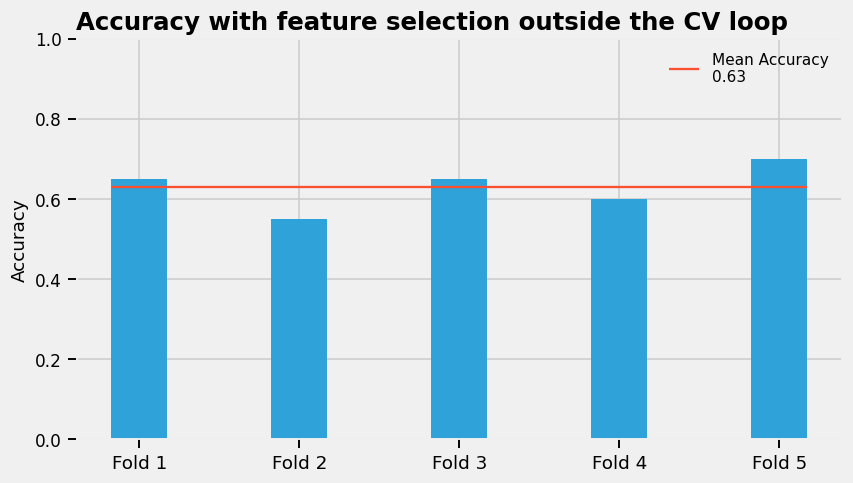

In [6]:
labels = ['Fold 1', 'Fold 2', 'Fold 3', 'Fold 4', 'Fold 5']

x = np.arange(len(labels))  # the label locations
width = 0.35  # the width of the bars

fig, ax = plt.subplots()
ax.bar(x, accuracy_scores, width)
ax.plot([x[0]-width/2, x[-1]+width/2], [np.mean(accuracy_scores), np.mean(accuracy_scores)], lw=1.5, color='#fc4f30', label='Mean Accuracy\n{:.2f}'.format(np.mean(accuracy_scores)))
ax.set_ylabel('Accuracy', fontsize=12)
ax.set_ylim([0, 1.])
ax.set_title('Accuracy for each cross-validation fold', fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=12)
ax.legend(frameon=False)
ax.set_title('Accuracy with feature selection outside the CV loop', fontsize=16, loc='left')
plt.show()

<p>Return to the slides for feature selection inside the CV loop.</p>

<a id="section2"></a>
<h2>2. Feature selection inside the CV loop</h2>
<p>How does selecting features within each fold change the result?</p>
<a id="Feature-Selection-Inside-CV-Loop"></a>
<a id="feature-selection-inside-cv-loop"></a>

In [7]:
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SelectKBest, chi2

# Setup
model = LogisticRegression(penalty=None)
five_fold = KFold(n_splits=5)
accuracy_scores = []

# Iterature thought cv-folds
for train_index, val_index in five_fold.split(X_new):
    
    # Select the 5 best features from X, y
    select = SelectKBest(chi2, k=2).fit(X.iloc[train_index, :], 
                                        np.ravel(y.iloc[train_index]))
    
    # Create reduced Feature set
    X_new = X.loc[:, select.get_support()]
    print('Selected features: {}'.format(X_new.columns.tolist()))

    # Fit model
    model.fit(X_new.iloc[train_index, :], 
              np.ravel(y.iloc[train_index]))

    # Append accuracy scores
    accuracy_scores.append(
        accuracy_score(y.iloc[val_index], 
                       model.predict(X_new.iloc[val_index, :])))

Selected features: [1819, 3584]
Selected features: [1519, 3584]
Selected features: [1192, 1819]
Selected features: [1819, 3817]
Selected features: [1949, 4095]


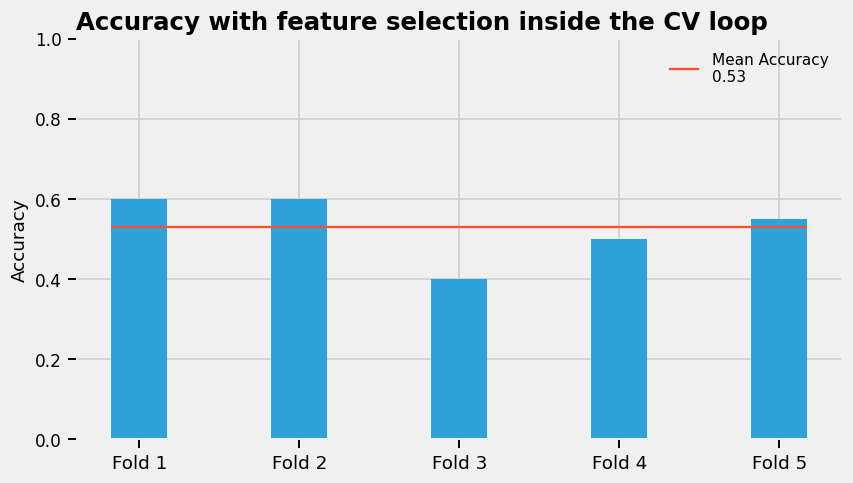

In [8]:
labels = ['Fold 1', 'Fold 2', 'Fold 3', 'Fold 4', 'Fold 5']

x = np.arange(len(labels))  # the label locations
width = 0.35  # the width of the bars

fig, ax = plt.subplots()
ax.bar(x, accuracy_scores, width)
ax.plot([x[0]-width/2, x[-1]+width/2], [np.mean(accuracy_scores), np.mean(accuracy_scores)], lw=1.5, color='#fc4f30', label='Mean Accuracy\n{:.2f}'.format(np.mean(accuracy_scores)))
ax.set_ylabel('Accuracy', fontsize=12)
ax.set_ylim([0, 1.])
ax.set_title('Accuracy for each cross-validation fold', fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=12)
ax.legend(frameon=False)
ax.set_title('Accuracy with feature selection inside the CV loop', fontsize=16, loc='left')
plt.show()

<p>Return to the slides to discuss which features to keep for the final model.</p>

<a id="section3"></a>
<h2>3. Diabetes dataset</h2>
<p>Which features are selected from the diabetes data?</p>
<a id="Diabetes-Dataset"></a>
<a id="diabetes-dataset"></a>

In [9]:
diabetes = pd.read_csv('diabetes.csv')
diabetes = diabetes.drop(['DiabetesPedigreeFunction'], axis=1)
diabetes.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,Age,Outcome
0,6,148,72,35,0,33.6,50,1
1,1,85,66,29,0,26.6,31,0
2,8,183,64,0,0,23.3,32,1
3,1,89,66,23,94,28.1,21,0
4,0,137,40,35,168,43.1,33,1


In [10]:
X = diabetes.iloc[:, 0:7]
y = diabetes.iloc[:, 7]

<h3>Feature Selection Inside CV Loop</h3>

In [11]:
# Setup
model = LogisticRegression(penalty=None)
five_fold = KFold(n_splits=5)
accuracy_scores = []

# Iterature thought cv-folds
for train_index, val_index in five_fold.split(X):
    
    # Select the 5 best features from X, y
    select = SelectKBest(chi2, k=4).fit(X.iloc[train_index, :], 
                                        np.ravel(y.iloc[train_index]))
    
    # Create reduced Feature set
    X_new = X.loc[:, select.get_support()]
    print('Selected features: {}'.format(X_new.columns.tolist()))

    # Fit model
    model.fit(X_new.iloc[train_index, :], 
              np.ravel(y.iloc[train_index]))

    # Append accuracy scores
    accuracy_scores.append(
        accuracy_score(y.iloc[val_index], 
                       model.predict(X_new.iloc[val_index, :])))

Selected features: ['Pregnancies', 'Glucose', 'Insulin', 'Age']
Selected features: ['Glucose', 'Insulin', 'BMI', 'Age']
Selected features: ['Glucose', 'Insulin', 'BMI', 'Age']
Selected features: ['Glucose', 'Insulin', 'BMI', 'Age']
Selected features: ['Glucose', 'Insulin', 'BMI', 'Age']


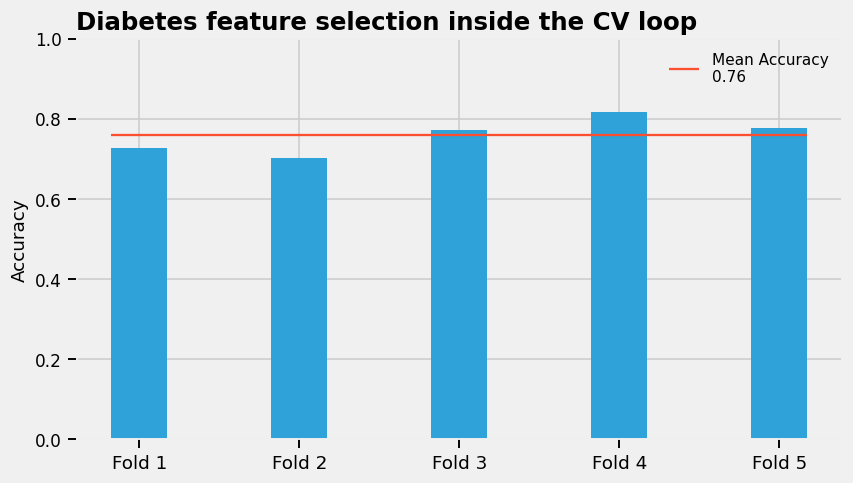

In [12]:
labels = ['Fold 1', 'Fold 2', 'Fold 3', 'Fold 4', 'Fold 5']

x = np.arange(len(labels))  # the label locations
width = 0.35  # the width of the bars

fig, ax = plt.subplots()
ax.bar(x, accuracy_scores, width)
ax.plot([x[0]-width/2, x[-1]+width/2], [np.mean(accuracy_scores), np.mean(accuracy_scores)], lw=1.5, color='#fc4f30', label='Mean Accuracy\n{:.2f}'.format(np.mean(accuracy_scores)))
ax.set_ylabel('Accuracy', fontsize=12)
ax.set_ylim([0, 1.])
ax.set_title('Accuracy for each cross-validation fold', fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=12)
ax.legend(frameon=False)
ax.set_title('Diabetes feature selection inside the CV loop', fontsize=16, loc='left')
plt.show()

<h3>Feature Selection Outside CV Loop</h3>

In [13]:
# Select the 5 best features from X, y
X_new = SelectKBest(chi2, k=2).fit_transform(X, np.ravel(y))
X_new = pd.DataFrame(X_new)

# Setup
model = LogisticRegression(penalty=None)
five_fold = KFold(n_splits=5)
accuracy_scores = []

# Iterature thought cv-folds
for train_index, val_index in five_fold.split(X_new):
    
    # Fit model
    model.fit(X_new.iloc[train_index, :], 
              np.ravel(y.iloc[train_index]))

    # Append accuracy scores
    accuracy_scores.append(
        accuracy_score(y.iloc[val_index], 
                       model.predict(X_new.iloc[val_index, :])))

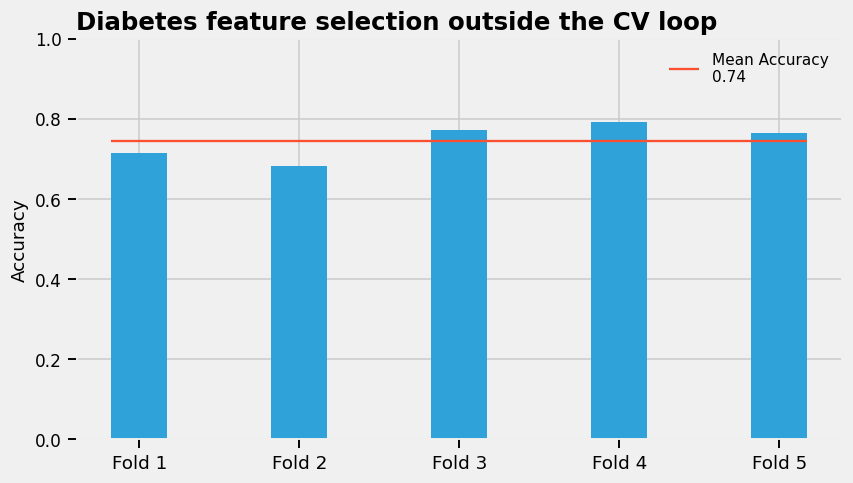

In [14]:
labels = ['Fold 1', 'Fold 2', 'Fold 3', 'Fold 4', 'Fold 5']

x = np.arange(len(labels))  # the label locations
width = 0.35  # the width of the bars

fig, ax = plt.subplots()
ax.bar(x, accuracy_scores, width)
ax.plot([x[0]-width/2, x[-1]+width/2], [np.mean(accuracy_scores), np.mean(accuracy_scores)], lw=1.5, color='#fc4f30', label='Mean Accuracy\n{:.2f}'.format(np.mean(accuracy_scores)))
ax.set_ylabel('Accuracy', fontsize=12)
ax.set_ylim([0, 1.])
ax.set_title('Accuracy for each cross-validation fold', fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=12)
ax.legend(frameon=False)
ax.set_title('Diabetes feature selection outside the CV loop', fontsize=16, loc='left')
plt.show()

<p>Return to the slides for hyperparameter tuning.</p>

<a id="section4"></a>
<h2>4. Hyperparameters</h2>
<p>Which model settings do we choose before fitting?</p>

In [15]:
print(model.get_params())

{'C': 1.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': 0.0, 'max_iter': 100, 'n_jobs': None, 'penalty': None, 'random_state': None, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}


In [16]:
print(model.coef_)

[[ 0.03692554 -0.00030452]]


In [17]:
print(model.intercept_)

[-5.20076524]



<a id="Hyper-Parameters"></a>
<a id="hyper-parameters"></a>
<h3>Model hyperparameters</h3>

In [18]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

print(model.get_params())

{'C': 1.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': 0.0, 'max_iter': 100, 'n_jobs': None, 'penalty': 'deprecated', 'random_state': None, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}


In [19]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier()

print(model.get_params())

{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': None, 'oob_score': False, 'random_state': None, 'verbose': 0, 'warm_start': False}


<p>Return to the slides for tuning methods.</p>

<a id="grid-search"></a>
<h2>5. Grid search</h2>
<p>How do validation scores vary across a grid of model settings?</p>

In [20]:
diabetes = pd.read_csv('diabetes.csv')
diabetes = diabetes.drop(['DiabetesPedigreeFunction'], axis=1)
diabetes.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,Age,Outcome
0,6,148,72,35,0,33.6,50,1
1,1,85,66,29,0,26.6,31,0
2,8,183,64,0,0,23.3,32,1
3,1,89,66,23,94,28.1,21,0
4,0,137,40,35,168,43.1,33,1


In [21]:
X = diabetes[['Glucose', 'Insulin', 'BMI']]
X.head()

,Glucose,Insulin,BMI
0,148,0,33.6
1,85,0,26.6
2,183,0,23.3
3,89,94,28.1
4,137,168,43.1


In [22]:
y = diabetes[['Outcome']]
y.head()

,Outcome
0,1
1,0
2,1
3,0
4,1


In [23]:
from sklearn.model_selection import GridSearchCV

model = LogisticRegression(max_iter=1000)

cv = KFold(n_splits=5)

param_grid = {'penalty': ('l1', 'l2', None),
              'fit_intercept': (True, False),
              'C' : (0.001, 0.01, 0.1, 1, 10, 100), 
              'class_weight': (None, 'balanced')}

# Match each penalty to a compatible solver.
search_settings = []
for penalty in param_grid['penalty']:
    settings = param_grid.copy()
    settings['penalty'] = [penalty]
    if penalty == 'l1':
        settings['solver'] = ['liblinear']
    else:
        settings['solver'] = ['lbfgs']
    search_settings.append(settings)

gs = GridSearchCV(estimator=model, 
                  param_grid=search_settings, 
                  scoring='accuracy',
                  cv=cv)
gs.fit(X, np.ravel(y))

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegre...max_iter=1000)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'C': (0.001, ...), 'class_weight': (None, ...), 'fit_intercept': (True, ...), 'penalty': ['l1'], ...}, {'C': (0.001, ...), 'class_weight': (None, ...), 'fit_intercept': (True, ...), 'penalty': ['l2'], ...}, ...]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split...shuffle=False)
,"ve

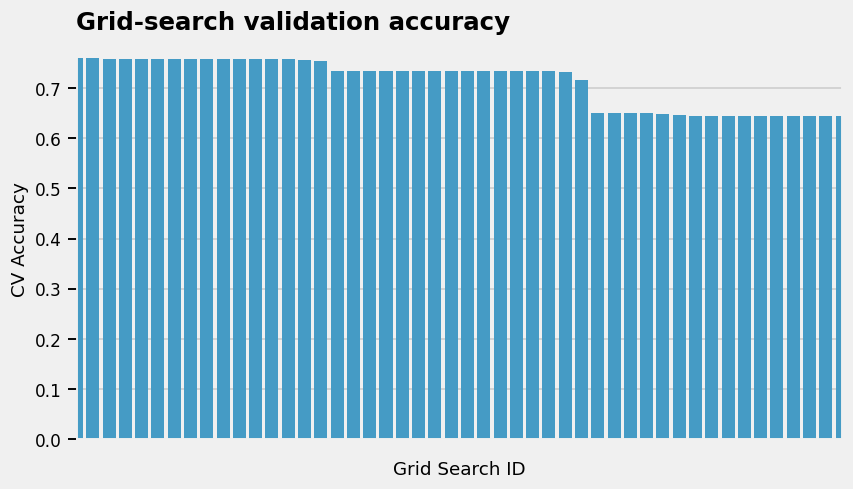

In [24]:
df = pd.DataFrame(gs.cv_results_).sort_values('mean_test_score', 
                                               ascending=False).reset_index(drop=True)
ax = sns.barplot(x=df.index, y='mean_test_score', data=df, color='#30A2DA')
ax.axes.xaxis.set_ticklabels([])
plt.tick_params(bottom=False)
ax.set_xlabel('Grid Search ID', fontsize=12)
ax.set_ylabel('CV Accuracy', fontsize=12)
ax.set_xlim([0, 47])
ax.set_title('Grid-search validation accuracy', fontsize=16, loc='left')
plt.show()

In [25]:
df.shape

(72, 18)

<p>Return to the slides to compare fold scores and introduce random search.</p>

<a id="random-search"></a>
<h2>6. Random search</h2>
<p>What happens when we sample model settings?</p>

In [26]:
from scipy.stats import loguniform
from sklearn.model_selection import RandomizedSearchCV

model = LogisticRegression(max_iter=1000)

cv = KFold(n_splits=5)

param_distributions = {'penalty': ('l1', 'l2', None),
                       'fit_intercept': (True, False),
                       'C' : loguniform(1e-3, 1e2), 
                       'class_weight': (None, 'balanced')}

# Match each penalty to a compatible solver.
search_settings = []
for penalty in param_distributions['penalty']:
    settings = param_distributions.copy()
    settings['penalty'] = [penalty]
    if penalty == 'l1':
        settings['solver'] = ['liblinear']
    else:
        settings['solver'] = ['lbfgs']
    search_settings.append(settings)

gs = RandomizedSearchCV(estimator=model, 
                        param_distributions=search_settings, 
                        n_iter=72,
                        scoring='accuracy',
                        cv=cv)
gs.fit(X, np.ravel(y))

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegre...max_iter=1000)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","[{'C': <scipy.stats....001DBE9B72510>, 'class_weight': (None, ...), 'fit_intercept': (True, ...), 'penalty': ['l1'], ...}, {'C': <scipy.stats....001DBE9B72510>, 'class_weight': (None, ...), 'fit_intercept': (True, ...), 'penalty': ['l2'], ...}, ...]"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",72
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits

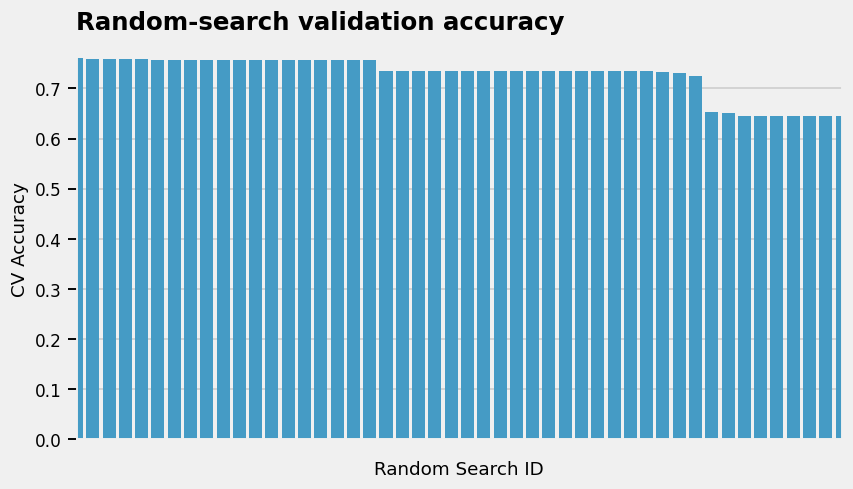

In [27]:
df = pd.DataFrame(gs.cv_results_).sort_values('mean_test_score', 
                                               ascending=False).reset_index(drop=True)
ax = sns.barplot(x=df.index, y='mean_test_score', data=df, color='#30A2DA')
ax.axes.xaxis.set_ticklabels([])
plt.tick_params(bottom=False)
ax.set_xlabel('Random Search ID', fontsize=12)
ax.set_ylabel('CV Accuracy', fontsize=12)
ax.set_xlim([0, 47])
ax.set_title('Random-search validation accuracy', fontsize=16, loc='left')
plt.show()

In [28]:
df.iloc[45:50]

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_C,param_class_weight,param_fit_intercept,param_penalty,param_solver,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
45,0.003312,0.000403,0.001206,0.000403,1.281911,None,False,l2,lbfgs,"{'C': 1.2819107468477373, 'class_weight': None...",0.642857,0.577922,0.642857,0.712418,0.647059,0.644623,0.042561,43
46,0.003549,0.000781,0.001810,0.000406,5.078480,None,False,l2,lbfgs,"{'C': 5.078480010246319, 'class_weight': None,...",0.642857,0.577922,0.642857,0.712418,0.647059,0.644623,0.042561,43
47,0.003516,0.001091,0.001604,0.000375,25.332971,None,False,None,lbfgs,"{'C': 25.332971225937136, 'class_weight': None...",0.642857,0.577922,0.642857,0.712418,0.647059,0.644623,0.042561,43
48,0.003875,0.000681,0.001339,0.000386,6.490369,None,False,l2,lbfgs,"{'C': 6.490369240306315, 'class_weight': None,...",0.642857,0.577922,0.642857,0.712418,0.647059,0.644623,0.042561,43
49,0.002578,0.000547,0.001428,0.000542,0.146199,None,False,l2,lbfgs,"{'C': 0.14619852452994656, 'class_weight': Non...",0.642857,0.577922,0.642857,0.712418,0.647059,0.644623,0.042561,43


In [29]:
df.shape

(72, 18)

<p>Return to the slides for informed search and the complete ML pipeline.</p>